# 06 · Optimización: dos modelos finales, dos propósitos

Se optimizan dos modelos con propósitos distintos:

- **Modelo interpretable**: usa solo las features de consenso (≥3 de 4
  modelos, notebook 03) — pocas variables, cada una con soporte en varias
  familias de algoritmos y significado químico directo.
- **Modelo de potencia bruta**: usa, para cada familia de modelo, su propio
  número óptimo de features (el `k` óptimo determinado por CV en el notebook
  03).

Para cada vía se optimizan LightGBM y XGBoost con Optuna, por validación
cruzada de 5 particiones. El criterio de elección entre familias no es solo
el R² de validación cruzada: **también se pesa el tiempo de entrenamiento**.
Un modelo que gana por una fracción de R² muy por debajo de su propia
variabilidad entre particiones (su desviación estándar de CV), pero tarda
varias veces más en entrenar, no es la mejor opción cuando el objetivo es
demostrar que se puede hacer buena química computacional en hardware modesto.
Concretamente: si el modelo más rápido queda dentro de una desviación
estándar del más lento, se prefiere el más rápido (la misma lógica de la
regla de un error estándar de Hastie, Tibshirani & Friedman, 2009, aplicada
ahora a la elección de familia de modelo en vez de al número de features).

El conjunto de prueba y la validación externa no participan en ninguna
decisión de este notebook — eso se reserva para el notebook 07, únicamente
como confirmación posterior (Cawley & Talbot, 2010).

Configuración global cargada
Semilla: 1
RESUMEN DE LOS CONJUNTOS DE DATOS

Entrenamiento (AqSolDB, depurado)
  Moléculas: 6,592
  logS: [-12.06, 1.97]  media=-2.929  sd=2.359

Validación interna (AqSolDB, SD=0)
  Moléculas: 1,316
  logS: [-13.17, 2.14]  media=-2.975  sd=2.411

Validación externa1 (Delaney/ESOL)
  Moléculas: 1,128
  logS: [-11.60, 1.58]  media=-3.050  sd=2.096

Validación externa2 (Tight_SC-2)
  Moléculas: 100
  logS: [-6.79, -1.18]  media=-4.027  sd=1.272

Validación externa3 (Loose_SC-2)
  Moléculas: 32
  logS: [-10.40, -1.24]  media=-5.241  sd=2.176


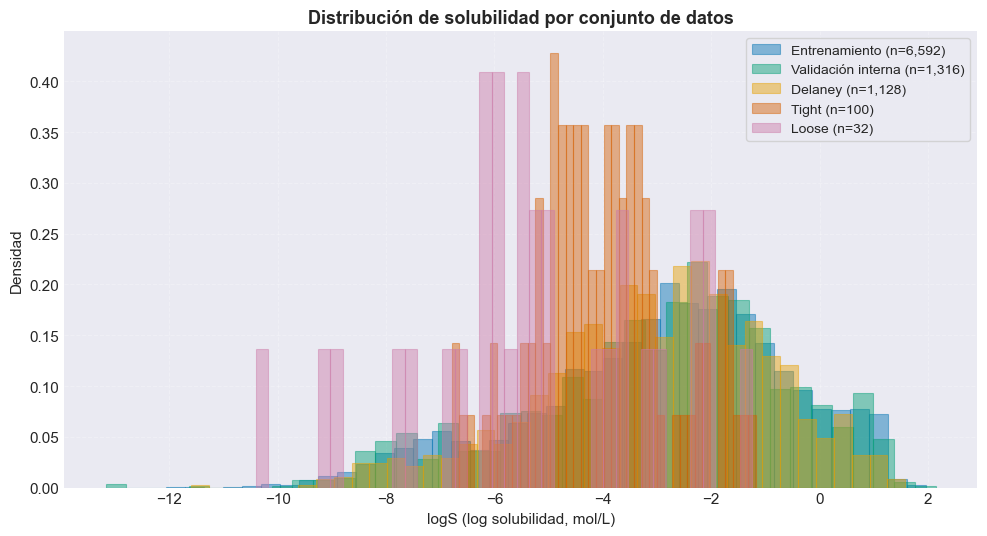

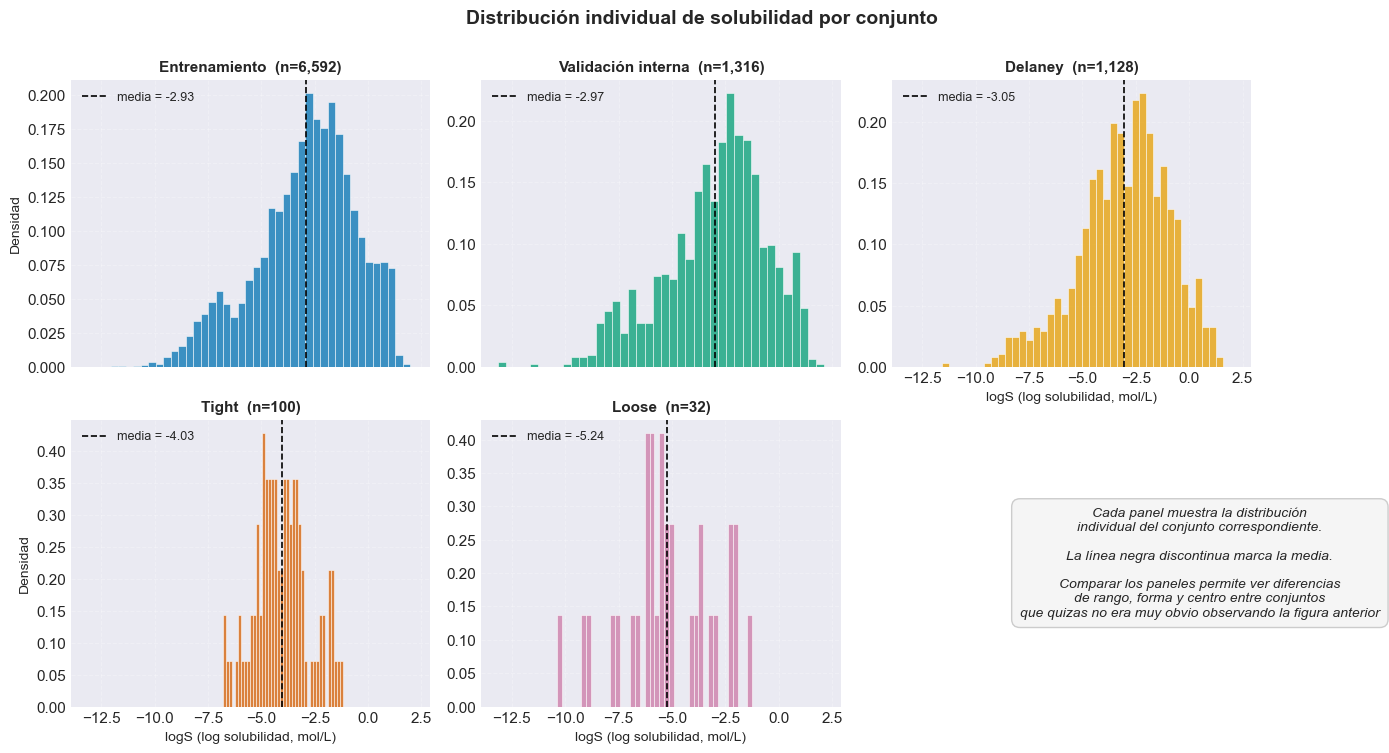

Features modelo interpretable (consenso >= 3/4): 13
k óptimo individual -- LightGBM: 29  |  XGBoost: 41


In [1]:
%run 02_configuracion_y_datos.ipynb

import optuna
import json
from sklearn.model_selection import cross_val_score, KFold
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from tqdm.auto import tqdm

datos_features = joblib.load('../resultados/features/seleccion_features.pkl')
features_interpretable = datos_features['features_finales']
top_features_por_modelo = datos_features['top_features_por_modelo']
k_optimo_por_modelo = datos_features['k_optimo_por_modelo']

excluir = ['ID', 'Name', 'InChI', 'InChIKey', 'SMILES',
           'Solubility', 'SD', 'Occurrences', 'Group', 'Ipc']
x_completo = df_entrenamiento[[c for c in df_entrenamiento.columns if c not in excluir]]
y = df_entrenamiento['Solubility']

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
N_TRIALS = 100

print(f"Features modelo interpretable (consenso >= {datos_features['criterio_consenso']}/4): {len(features_interpretable)}")
print(f"k óptimo individual -- LightGBM: {k_optimo_por_modelo['LightGBM']['k']}  |  XGBoost: {k_optimo_por_modelo['XGBoost']['k']}")

## Función de optimización 
La búsqueda de hiperparámetros se realiza con Optuna, un framework para la optimización automatizada de hiperparámetros (Akiba et al., 2019).

In [2]:
def optimizar_modelo(nombre_familia, x, y, n_trials=N_TRIALS, descripcion=''):
    """Optimiza hiperparametros de LightGBM o XGBoost por validacion cruzada
    con Optuna. Devuelve el estudio, el modelo final reentrenado con todos los
    datos, el tiempo total de busqueda, y la desviacion estandar de CV del
    modelo ganador (para poder comparar familias considerando tanto el
    rendimiento como su variabilidad)."""

    def construir_modelo(params):
        if nombre_familia == 'LightGBM':
            p = dict(params); p.update({'random_state': RANDOM_STATE, 'n_jobs': -1, 'verbosity': -1})
            return LGBMRegressor(**p)
        else:
            p = dict(params); p.update({'random_state': RANDOM_STATE, 'n_jobs': -1, 'verbosity': 0})
            return XGBRegressor(**p)

    def objetivo(trial):
        if nombre_familia == 'LightGBM':
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
                'max_depth': trial.suggest_int('max_depth', 3, 10),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                'feature_fraction': trial.suggest_float('feature_fraction', 0.6, 1.0),
                'reg_alpha': trial.suggest_float('reg_alpha', 0.001, 10, log=True),
                'reg_lambda': trial.suggest_float('reg_lambda', 0.001, 10, log=True),
                'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
            }
        else:
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
                'max_depth': trial.suggest_int('max_depth', 3, 10),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
                'reg_alpha': trial.suggest_float('reg_alpha', 0.001, 10, log=True),
                'reg_lambda': trial.suggest_float('reg_lambda', 0.001, 10, log=True),
                'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
            }
        modelo = construir_modelo(params)
        return cross_val_score(modelo, x, y, cv=kf, scoring='r2', n_jobs=-1).mean()

    estudio = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    inicio = time.time()
    barra = tqdm(range(n_trials), desc=f'Optuna {nombre_familia} {descripcion}')
    for _ in barra:
        trial = estudio.ask()
        valor = objetivo(trial)
        estudio.tell(trial, valor)
        barra.set_postfix(mejor_r2_cv=f"{estudio.best_value:.4f}")
    tiempo_busqueda = time.time() - inicio

    # Un ultimo CV con los mejores hiperparametros para conocer tambien la
    # desviacion estandar (Optuna solo registra la media de cada trial)
    modelo_final = construir_modelo(estudio.best_params)
    scores_finales = cross_val_score(modelo_final, x, y, cv=kf, scoring='r2', n_jobs=-1)

    inicio_fit = time.time()
    modelo_final.fit(x, y)
    tiempo_entrenamiento_final = time.time() - inicio_fit

    return {
        'estudio': estudio,
        'modelo': modelo_final,
        'r2_cv_media': scores_finales.mean(),
        'r2_cv_std': scores_finales.std(),
        'tiempo_busqueda_s': tiempo_busqueda,
        'tiempo_entrenamiento_s': tiempo_entrenamiento_final,
    }


def elegir_familia(resultado_lgbm, resultado_xgb):
    """Elige entre LightGBM y XGBoost pesando rendimiento Y tiempo.

    Regla: si el modelo mas rapido esta dentro de una desviacion estandar de
    CV del mas lento, se prefiere el mas rapido -- la diferencia de R2 no es
    distinguible de la variabilidad propia de la validacion cruzada, y pagar
    varias veces mas tiempo de computo por una diferencia estadisticamente
    invisible va en contra del objetivo de este proyecto.
    """
    lento, rapido = (
        (resultado_lgbm, resultado_xgb) if resultado_lgbm['tiempo_busqueda_s'] > resultado_xgb['tiempo_busqueda_s']
        else (resultado_xgb, resultado_lgbm)
    )
    diferencia_r2 = lento['r2_cv_media'] - rapido['r2_cv_media']

    if diferencia_r2 <= lento['r2_cv_std']:
        return rapido, f"gana el más rápido: diferencia de R² ({diferencia_r2:.4f}) menor que 1 SD de CV del más lento ({lento['r2_cv_std']:.4f})"
    else:
        return lento, f"gana el de mejor R²: la diferencia ({diferencia_r2:.4f}) supera 1 SD de CV ({lento['r2_cv_std']:.4f}), no se explica por variabilidad de CV"

## Vía 1 · Modelo interpretable (features de consenso)

In [3]:
x_interpretable = x_completo[features_interpretable]

resultado_lgbm_interp = optimizar_modelo('LightGBM', x_interpretable, y, descripcion='(interpretable)')
print(f"LightGBM interpretable: R²(CV) = {resultado_lgbm_interp['r2_cv_media']:.4f} ± {resultado_lgbm_interp['r2_cv_std']:.4f}  "
      f"({resultado_lgbm_interp['tiempo_busqueda_s']:.1f}s)")

resultado_xgb_interp = optimizar_modelo('XGBoost', x_interpretable, y, descripcion='(interpretable)')
print(f"XGBoost interpretable:  R²(CV) = {resultado_xgb_interp['r2_cv_media']:.4f} ± {resultado_xgb_interp['r2_cv_std']:.4f}  "
      f"({resultado_xgb_interp['tiempo_busqueda_s']:.1f}s)")

ganador_interp, razon_interp = elegir_familia(resultado_lgbm_interp, resultado_xgb_interp)
familia_interpretable = 'LightGBM' if ganador_interp is resultado_lgbm_interp else 'XGBoost'
modelo_interpretable = ganador_interp['modelo']
r2_cv_interpretable = ganador_interp['r2_cv_media']

print(f"\nDecisión: {razon_interp}")
print(f"Modelo interpretable final: {familia_interpretable}  (R²(CV) = {r2_cv_interpretable:.4f}, "
      f"tiempo de búsqueda = {ganador_interp['tiempo_busqueda_s']:.1f}s)")

[I 2026-10-20 16:24:41,491] A new study created in memory with name: no-name-1757cfb0-ddea-4487-94d3-a4ef4508aef1


Optuna LightGBM (interpretable):   0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-10-20 16:32:51,810] A new study created in memory with name: no-name-c87ebcf4-70fc-43ec-9ed1-4bd43e4a00f8


LightGBM interpretable: R²(CV) = 0.8273 ± 0.0068  (483.2s)


Optuna XGBoost (interpretable):   0%|          | 0/100 [00:00<?, ?it/s]

XGBoost interpretable:  R²(CV) = 0.8306 ± 0.0066  (1027.1s)

Decisión: gana el más rápido: diferencia de R² (0.0034) menor que 1 SD de CV del más lento (0.0066)
Modelo interpretable final: LightGBM  (R²(CV) = 0.8273, tiempo de búsqueda = 483.2s)


## Vía 2 · Modelo de potencia bruta (k óptimo propio de cada familia)

LightGBM y XGBoost no comparten el mismo conjunto de features aquí: cada uno
usa el `k` óptimo que su propia curva de validación cruzada identificó en el
notebook 03.

In [4]:
x_bruto_lgbm = x_completo[top_features_por_modelo['LightGBM']]
x_bruto_xgb = x_completo[top_features_por_modelo['XGBoost']]

print(f"LightGBM usará su k óptimo: {len(top_features_por_modelo['LightGBM'])} features")
print(f"XGBoost usará su k óptimo:  {len(top_features_por_modelo['XGBoost'])} features")

resultado_lgbm_bruto = optimizar_modelo('LightGBM', x_bruto_lgbm, y, descripcion='(potencia bruta)')
print(f"LightGBM potencia bruta: R²(CV) = {resultado_lgbm_bruto['r2_cv_media']:.4f} ± {resultado_lgbm_bruto['r2_cv_std']:.4f}  "
      f"({resultado_lgbm_bruto['tiempo_busqueda_s']:.1f}s)")

resultado_xgb_bruto = optimizar_modelo('XGBoost', x_bruto_xgb, y, descripcion='(potencia bruta)')
print(f"XGBoost potencia bruta:  R²(CV) = {resultado_xgb_bruto['r2_cv_media']:.4f} ± {resultado_xgb_bruto['r2_cv_std']:.4f}  "
      f"({resultado_xgb_bruto['tiempo_busqueda_s']:.1f}s)")

ganador_bruto, razon_bruto = elegir_familia(resultado_lgbm_bruto, resultado_xgb_bruto)
familia_bruto = 'LightGBM' if ganador_bruto is resultado_lgbm_bruto else 'XGBoost'
modelo_bruto = ganador_bruto['modelo']
features_bruto = top_features_por_modelo[familia_bruto]
r2_cv_bruto = ganador_bruto['r2_cv_media']

print(f"\nDecisión: {razon_bruto}")
print(f"Modelo de potencia bruta final: {familia_bruto}  ({len(features_bruto)} features, R²(CV) = {r2_cv_bruto:.4f}, "
      f"tiempo de búsqueda = {ganador_bruto['tiempo_busqueda_s']:.1f}s)")

[I 2026-10-20 16:50:12,436] A new study created in memory with name: no-name-46afe9b6-a10b-42f7-b87c-3c0ab919123b


LightGBM usará su k óptimo: 29 features
XGBoost usará su k óptimo:  41 features


Optuna LightGBM (potencia bruta):   0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-10-20 17:05:54,987] A new study created in memory with name: no-name-2dbed41e-0e5c-493d-b867-f0d7d2bd4465


LightGBM potencia bruta: R²(CV) = 0.8502 ± 0.0049  (932.4s)


Optuna XGBoost (potencia bruta):   0%|          | 0/100 [00:00<?, ?it/s]

XGBoost potencia bruta:  R²(CV) = 0.8478 ± 0.0067  (2059.3s)

Decisión: gana el más rápido: diferencia de R² (-0.0024) menor que 1 SD de CV del más lento (0.0067)
Modelo de potencia bruta final: LightGBM  (29 features, R²(CV) = 0.8502, tiempo de búsqueda = 932.4s)


## Comparación de las cuatro combinaciones

           vía  familia  n_features  r2_cv  tiempo_s
 Interpretable LightGBM          13 0.8273  483.2112
 Interpretable  XGBoost          13 0.8306 1027.0993
Potencia bruta LightGBM          29 0.8502  932.4254
Potencia bruta  XGBoost          41 0.8478 2059.3104


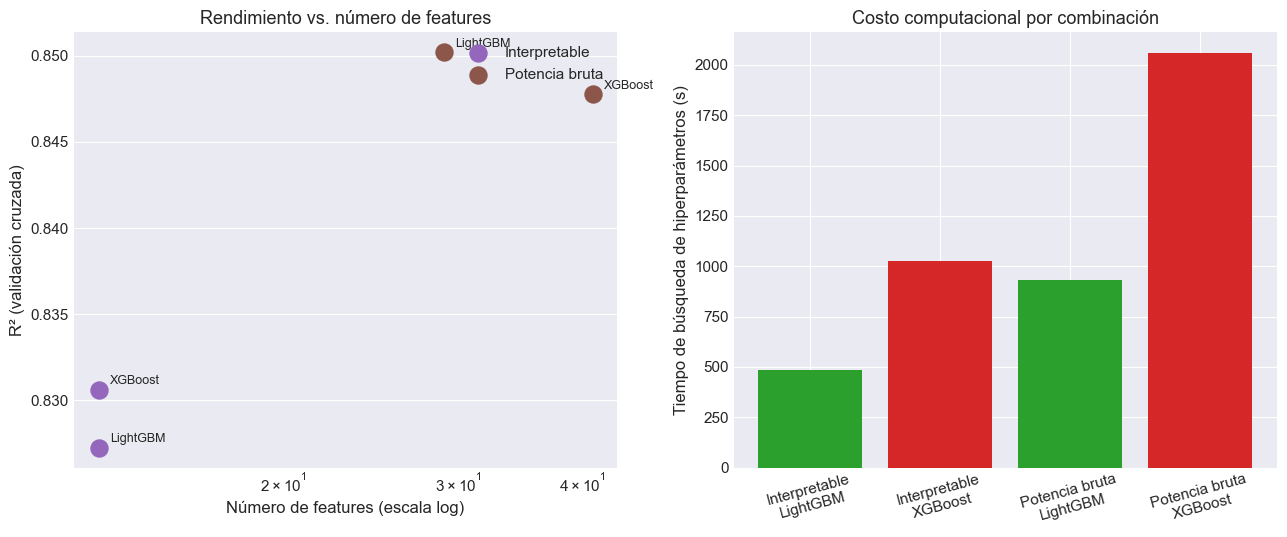

In [5]:
comparacion_cv = pd.DataFrame([
    {'vía': 'Interpretable', 'familia': 'LightGBM', 'n_features': len(features_interpretable),
     'r2_cv': resultado_lgbm_interp['r2_cv_media'], 'tiempo_s': resultado_lgbm_interp['tiempo_busqueda_s']},
    {'vía': 'Interpretable', 'familia': 'XGBoost', 'n_features': len(features_interpretable),
     'r2_cv': resultado_xgb_interp['r2_cv_media'], 'tiempo_s': resultado_xgb_interp['tiempo_busqueda_s']},
    {'vía': 'Potencia bruta', 'familia': 'LightGBM', 'n_features': len(top_features_por_modelo['LightGBM']),
     'r2_cv': resultado_lgbm_bruto['r2_cv_media'], 'tiempo_s': resultado_lgbm_bruto['tiempo_busqueda_s']},
    {'vía': 'Potencia bruta', 'familia': 'XGBoost', 'n_features': len(top_features_por_modelo['XGBoost']),
     'r2_cv': resultado_xgb_bruto['r2_cv_media'], 'tiempo_s': resultado_xgb_bruto['tiempo_busqueda_s']},
])
print(comparacion_cv.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for via, color in [('Interpretable', COLORES['Interpretable']), ('Potencia bruta', COLORES['Potencia bruta'])]:
    subset = comparacion_cv[comparacion_cv['vía'] == via]
    axes[0].scatter(subset['n_features'], subset['r2_cv'], s=150, color=color, label=via)
    for _, fila in subset.iterrows():
        axes[0].annotate(fila['familia'], (fila['n_features'], fila['r2_cv']), textcoords="offset points", xytext=(8, 4), fontsize=9)

axes[0].set_xlabel('Número de features (escala log)')
axes[0].set_xscale('log')
axes[0].set_ylabel('R² (validación cruzada)')
axes[0].set_title('Rendimiento vs. número de features')
axes[0].legend()

colores_barra = ['#d62728' if f == 'XGBoost' else '#2ca02c' for f in comparacion_cv['familia']]
etiquetas = comparacion_cv['vía'] + '\n' + comparacion_cv['familia']
axes[1].bar(etiquetas, comparacion_cv['tiempo_s'], color=colores_barra)
axes[1].set_ylabel('Tiempo de búsqueda de hiperparámetros (s)')
axes[1].set_title('Costo computacional por combinación')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
os.makedirs('../resultados/graficos', exist_ok=True)
plt.savefig('../resultados/graficos/08_comparacion_via_interpretable_vs_bruta.png', dpi=150)
plt.show()

## Guardar los dos modelos finales

A partir de aquí, ambos modelos quedan congelados: no se vuelven a
re-entrenar ni a re-seleccionar mirando la validación externa. El notebook 07
los evalúa una sola vez, con fines de reporte.

In [6]:
os.makedirs('../resultados/modelos_finales', exist_ok=True)

joblib.dump(modelo_interpretable, '../resultados/modelos_finales/modelo_interpretable.pkl')
joblib.dump(modelo_bruto, '../resultados/modelos_finales/modelo_potencia_bruta.pkl')
joblib.dump(features_interpretable, '../resultados/modelos_finales/features_interpretable.pkl')
joblib.dump(features_bruto, '../resultados/modelos_finales/features_potencia_bruta.pkl')

with open('../resultados/decision_modelos_finales.txt', 'w') as f:
    f.write("DECISION DE MODELOS FINALES (criterio: R2 de CV + tiempo de computo)\n")
    f.write("="*60 + "\n\n")
    f.write(f"MODELO INTERPRETABLE\n")
    f.write(f"  Familia: {familia_interpretable}\n")
    f.write(f"  Features: {len(features_interpretable)} (consenso >= {datos_features['criterio_consenso']}/4 familias, notebook 03)\n")
    f.write(f"  R2(CV): {r2_cv_interpretable:.4f}\n")
    f.write(f"  Razon: {razon_interp}\n\n")
    f.write(f"MODELO DE POTENCIA BRUTA\n")
    f.write(f"  Familia: {familia_bruto}\n")
    f.write(f"  Features: {len(features_bruto)} (k optimo propio de {familia_bruto}, notebook 03)\n")
    f.write(f"  R2(CV): {r2_cv_bruto:.4f}\n")
    f.write(f"  Razon: {razon_bruto}\n\n")
    f.write("Ninguna decision se tomo mirando la validacion externa (Delaney)\n")
    f.write("ese se reservan para el notebook 07, con fines\n")
    f.write("exclusivamente de reporte.\n")

json.dump(resultado_lgbm_interp['estudio'].best_params, open('../resultados/mejores_parametros_lightgbm_interpretable.json', 'w'), indent=2)
json.dump(resultado_xgb_interp['estudio'].best_params, open('../resultados/mejores_parametros_xgboost_interpretable.json', 'w'), indent=2)
json.dump(resultado_lgbm_bruto['estudio'].best_params, open('../resultados/mejores_parametros_lightgbm_bruto.json', 'w'), indent=2)
json.dump(resultado_xgb_bruto['estudio'].best_params, open('../resultados/mejores_parametros_xgboost_bruto.json', 'w'), indent=2)

print("Modelos finales guardados en ../resultados/modelos_finales/")
print(open('../resultados/decision_modelos_finales.txt').read())

Modelos finales guardados en ../resultados/modelos_finales/
DECISION DE MODELOS FINALES (criterio: R2 de CV + tiempo de computo)

MODELO INTERPRETABLE
  Familia: LightGBM
  Features: 13 (consenso >= 3/4 familias, notebook 03)
  R2(CV): 0.8273
  Razon: gana el más rápido: diferencia de R² (0.0034) menor que 1 SD de CV del más lento (0.0066)

MODELO DE POTENCIA BRUTA
  Familia: LightGBM
  Features: 29 (k optimo propio de LightGBM, notebook 03)
  R2(CV): 0.8502
  Razon: gana el más rápido: diferencia de R² (-0.0024) menor que 1 SD de CV del más lento (0.0067)

Ninguna decision se tomo mirando la validacion externa (Delaney)
ese se reservan para el notebook 07, con fines
exclusivamente de reporte.

